## Disclaimer

This content of this repository is free to use for everybody. Carl Zeiss Microscopy GmbH's ZEN software undertakes no warranty concerning the use of those scripts, image analysis settings and ZEN experiments. Use them on your own risk.

**By using any of those examples you agree to this disclaimer.**

In [1]:
import os
import random
import sys
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import onnxruntime as onnx_rt
from czmodel.core.util._extract_model import extract_czann_model
from skimage.io import imread

# Make the shared utility importable from any workshop subdirectory.
for utility_dir in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
    if (utility_dir / "workshop_utils.py").is_file():
        if str(utility_dir) not in sys.path:
            sys.path.insert(0, str(utility_dir))
        break
else:
    raise FileNotFoundError("Start from the workshop root or a subdirectory.")

from workshop_utils import initialize_workshop

workshop_root, project_dir, data_dir, model_dir = initialize_workshop(
    "deep_learning"
)

Kernel Python: f:\Pixi_Projects\zen_czi\smartmicroscopy_2026-11\.pixi\envs\default\python.exe
Workshop: F:\Pixi_Projects\zen_czi\smartmicroscopy_2026-11
Project: F:\Pixi_Projects\zen_czi\smartmicroscopy_2026-11\examples\deep_learning
Data: F:\Pixi_Projects\zen_czi\smartmicroscopy_2026-11\data
Model: F:\Pixi_Projects\zen_czi\smartmicroscopy_2026-11\data\DL_models


In [3]:
# Folder containing the input images
IMAGES_FOLDER = str(workshop_root / "data" / "nucleus_data/images")

# Folder containing the ground truth regression labels
# Regression labels contain a real number for each pixel
MASKS_FOLDER = str(workshop_root / "data" / "nucleus_data/labels")

czann_filepath_local = os.path.join(os.getcwd(), model_dir / "cyto2022_nuc2.czann")

print(f"Local CZANN path: {czann_filepath_local}")
print(f"local CZANN exists: {os.path.exists(czann_filepath_local)}")

Local CZANN path: F:\Pixi_Projects\zen_czi\smartmicroscopy_2026-11\data\DL_models\cyto2022_nuc2.czann
local CZANN exists: True


In [4]:
# get the sample images
sample_images = sorted([os.path.join(IMAGES_FOLDER, f) for f in os.listdir(IMAGES_FOLDER)
                        if os.path.isfile(os.path.join(IMAGES_FOLDER, f))])

# get the masks
sample_masks = sorted([os.path.join(MASKS_FOLDER, f) for f in os.listdir(MASKS_FOLDER)
                       if os.path.isfile(os.path.join(MASKS_FOLDER, f))])

In [6]:
def predict_one(sess: onnx_rt.InferenceSession, batch_elem: np.ndarray) -> np.ndarray:
    """Predicts with a batch size of 1 to not risk memory issues.

    Arguments:
        sess: The inference session containing the loaded model.
        batch_elem: One element of a batch to be used for prediction.

    Returns:
        The prediction for the provided batch element.
    """
    batch_elem = batch_elem[np.newaxis]
    input_name = sess.get_inputs()[0].name
    output_name = sess.get_outputs()[0].name

    # ONNX can only handle float32
    batch_elem = batch_elem.astype(np.float32)
    input_dict = {input_name: batch_elem}
    result = sess.run([output_name], input_dict)[0]
    if not isinstance(result, np.ndarray):
        raise TypeError(f"Expected a NumPy array from ONNX inference, got {type(result).__name__}")

    return result[0]

In [7]:
# extract the model information and path and to the prediction
with tempfile.TemporaryDirectory() as temp_path:
    
    # get the model metadata and the path
    model_metadata, model_path = extract_czann_model(path=czann_filepath_local, target_dir=Path(temp_path))

    # get model metadata as dictionary
    model_metadata_dict = model_metadata._asdict()
    for k,v in model_metadata_dict.items():
        print(k, "=", v)

    # get the input shape
    shp = model_metadata.input_shape

    # create an ONNX session and get the input shape
    # use either "CUDAExecutionProvider" or "CPUExecutionProvider"]
    sess = onnx_rt.InferenceSession(str(model_path), providers=["CPUExecutionProvider"])
    #sess = onnx_rt.InferenceSession(str(model_path), providers=[("CUDAExecutionProvider", {"cudnn_conv_algo_search": "DEFAULT"})])

model_type = ModelType.SINGLE_CLASS_SEMANTIC_SEGMENTATION
input_shape = [1024, 1024, 1]
output_shape = [1024, 1024, 2]
model_id = 30c3f719-a7ac-41a3-9204-b6a026ea5b5a
min_overlap = [128, 128]
classes = ['background', 'nuc']
model_name = APEER-trained model
scaling = None


Text(0.5, 1.0, 'Label Mask')

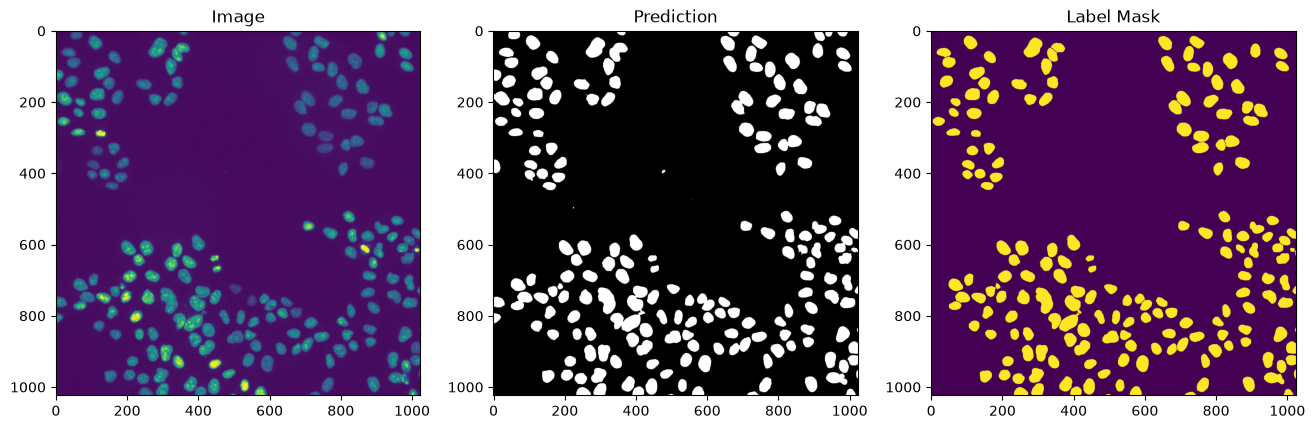

In [8]:
# just re-execute the cell to display a different image
# select an a random image
id = random.randint(0, len(sample_images))

# read images and scale
img = imread(sample_images[id])/(2**16 - 1)
mask = imread(sample_masks[id])

# cut input to fit the model
img = img[0: shp[0], 0:shp[1]]
mask = mask[0: shp[0], 0:shp[1]]

# run the actual prediction
pred = predict_one(sess, img[..., np.newaxis])

fig, (ax1, ax2, ax3) = plt.subplots(1, 3)
fig.set_figwidth(16)

# show images and set titles
ax1.imshow(img, vmin=0, vmax=0.05)
ax2.imshow(pred[..., 1], cmap="gray")
ax3.imshow(mask)

ax1.set_title('Image')
ax2.set_title('Prediction')
ax3.set_title('Label Mask')